# ==============================================================
# STEP 1: ENVIRONMENT SETUP & DEPENDENCIES
# ==============================================================

In [ ]:
import os
import sys
import gc
import json
import random
import shutil
from pathlib import Path

In [ ]:
# Package installations for Google Colab environment
!pip install -q split-folders scikit-learn matplotlib seaborn pillow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
import splitfolders
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set seed for reproducibility across libraries
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Available: {gpus[0].device_type} - {tf.test.gpu_device_name()}")
    # Enable dynamic memory growth to prevent sudden OOM allocation
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("WARNING: No GPU detected. Training may be significantly slow.")

TensorFlow Version: 2.20.0
GPU Available: GPU - /device:GPU:0


# ==============================================================
# STEP 2: MOUNT GOOGLE DRIVE & VERIFY DATASET
# ==============================================================

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive mounted successfully.")
except Exception as e:
    print(f"Drive mounting skipped or failed: {e}")

# Configurable File Paths
DRIVE_ZIP_PATH = Path('/content/drive/MyDrive/cleaned_dataset.zip')
EXTRACT_TARGET_DIR = Path('/content/plant_data')
DATASET_DIR = EXTRACT_TARGET_DIR / 'cleaned_dataset'
SPLIT_DIR = Path('/content/split_data')
MODEL_SAVE_PATH = Path('/content/drive/MyDrive/plant_disease_efficientnetb0.keras')
CLASS_JSON_PATH = Path('/content/drive/MyDrive/plant_disease_classes.json')

# Path Verification
if not DRIVE_ZIP_PATH.exists():
    print(f"ERROR: Dataset ZIP file not found at '{DRIVE_ZIP_PATH}'.")
    print("Please ensure your dataset is placed at the specified Google Drive location.")
else:
    print(f"Verified dataset ZIP archive exists at: {DRIVE_ZIP_PATH}")

# ==============================================================
# STEP 3: EXTRACT DATASET
# ==============================================================

In [ ]:
if not DATASET_DIR.exists():
    if DRIVE_ZIP_PATH.exists():
        print(f"Extracting dataset from {DRIVE_ZIP_PATH} to {EXTRACT_TARGET_DIR}...")
        EXTRACT_TARGET_DIR.mkdir(parents=True, exist_ok=True)
        shutil.unpack_archive(str(DRIVE_ZIP_PATH), str(EXTRACT_TARGET_DIR))
        print("Extraction complete.")
    else:
        raise FileNotFoundError(f"Cannot extract: {DRIVE_ZIP_PATH} does not exist.")
else:
    print(f"Dataset directory already exists at '{DATASET_DIR}'. Skipping extraction.")

# Verify nested directory structure after extraction
if not DATASET_DIR.exists():
    # Handle edge case where archive extracts directly into plant_data root
    subdirs = [d for d in EXTRACT_TARGET_DIR.iterdir() if d.is_dir()]
    if len(subdirs) == 1 and subdirs[0].name != 'cleaned_dataset':
        DATASET_DIR = subdirs[0]

print(f"Active raw dataset directory: {DATASET_DIR}")

Extracting dataset from /content/drive/MyDrive/cleaned_dataset.zip to /content/plant_data...
Extraction complete.
Active raw dataset directory: /content/plant_data/cleaned_dataset


# ==============================================================
# STEP 4: INSPECT DATASET & VISUALIZE
# ==============================================================



--- DATASET SUMMARY ---
Total Disease Classes: 38
Total Valid Images:    54284



/tmp/ipykernel_1456/2577523603.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_counts.values()), y=list(class_counts.keys()), palette="viridis")


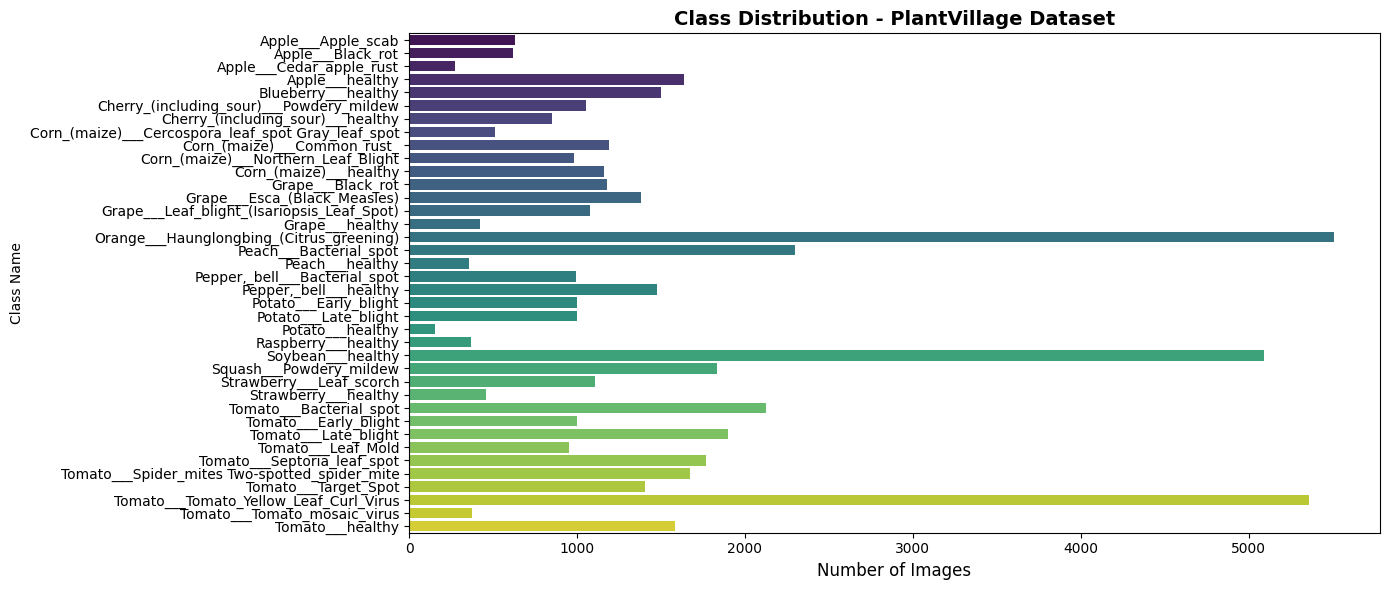

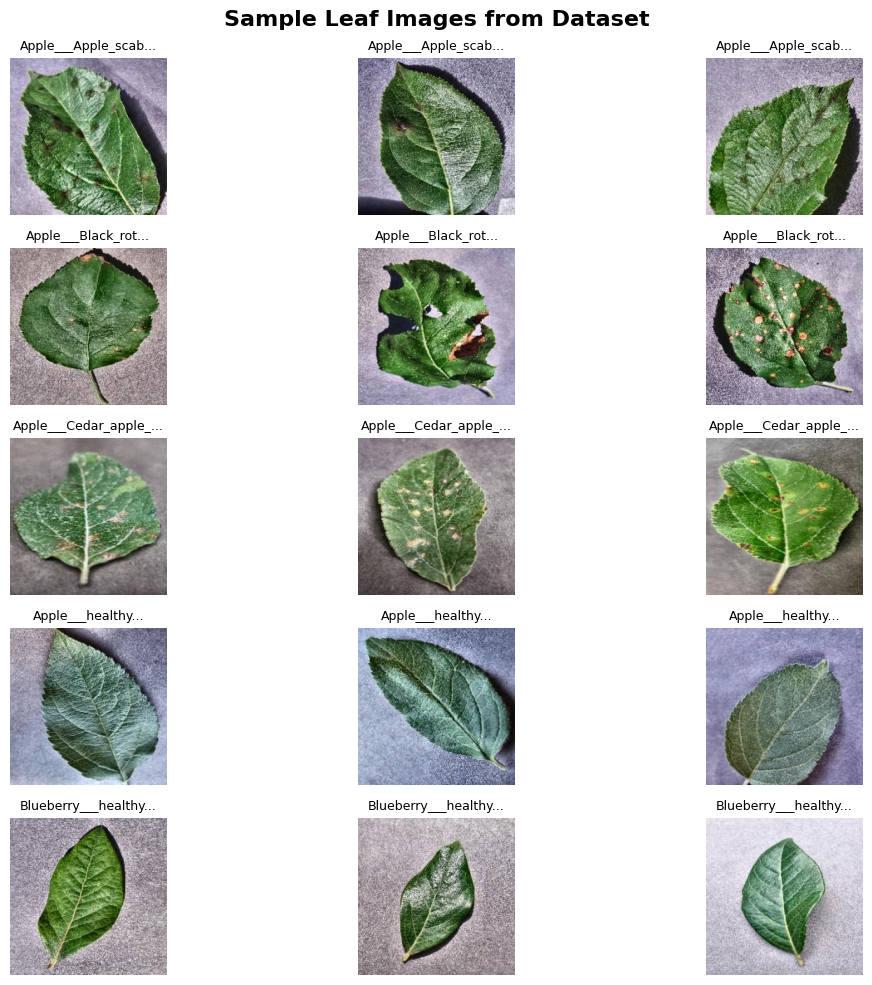

In [ ]:
class_folders = sorted([d for d in DATASET_DIR.iterdir() if d.is_dir()])
num_classes = len(class_folders)

class_counts = {}
total_images = 0
for folder in class_folders:
    valid_images = [f for f in folder.glob('*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']]
    count = len(valid_images)
    class_counts[folder.name] = count
    total_images += count

print(f"\n--- DATASET SUMMARY ---")
print(f"Total Disease Classes: {num_classes}")
print(f"Total Valid Images:    {total_images}\n")

# Distribution Plot
plt.figure(figsize=(14, 6))
sns.barplot(x=list(class_counts.values()), y=list(class_counts.keys()), palette="viridis")
plt.title("Class Distribution - PlantVillage Dataset", fontsize=14, fontweight='bold')
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Class Name", fontsize=10)
plt.tight_layout()
plt.show()

# Visualize Sample Images per Class
fig, axes = plt.subplots(nrows=min(5, num_classes), ncols=3, figsize=(12, 10))
fig.suptitle("Sample Leaf Images from Dataset", fontsize=16, fontweight='bold')
selected_classes = class_folders[:5]

for i, folder in enumerate(selected_classes):
    sample_imgs = list(folder.glob('*'))[:3]
    for j, img_path in enumerate(sample_imgs):
        ax = axes[i, j] if min(5, num_classes) > 1 else axes[j]
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(f"{folder.name[:20]}...", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

# ==============================================================
# STEP 5: SPLIT DATASET (70% Train, 15% Val, 15% Test)
# ==============================================================

In [ ]:
TRAIN_DIR = SPLIT_DIR / 'train'
VAL_DIR = SPLIT_DIR / 'val'
TEST_DIR = SPLIT_DIR / 'test'

if not (TRAIN_DIR.exists() and VAL_DIR.exists() and TEST_DIR.exists()):
    print(f"\nSplitting dataset (70% Train, 15% Val, 15% Test) into {SPLIT_DIR}...")
    splitfolders.ratio(
        str(DATASET_DIR),
        output=str(SPLIT_DIR),
        seed=SEED,
        ratio=(0.70, 0.15, 0.15),
        group_prefix=None
    )
    print("Dataset splitting completed.")
else:
    print(f"\nSplit dataset directory structure verified at '{SPLIT_DIR}'. Skipping split.")

train_count = len(list(TRAIN_DIR.rglob('*.*')))
val_count = len(list(VAL_DIR.rglob('*.*')))
test_count = len(list(TEST_DIR.rglob('*.*')))

print(f"Images in Training Set:   {train_count}")
print(f"Images in Validation Set: {val_count}")
print(f"Images in Test Set:       {test_count}")


Splitting dataset (70% Train, 15% Val, 15% Test) into /content/split_data...


Copying files: 54284 files [00:53, 1018.98 files/s]


Dataset splitting completed.
Images in Training Set:   37982
Images in Validation Set: 8126
Images in Test Set:       8176


# ==============================================================
# STEP 6: LOAD DATASETS USING TF.DATA
# ==============================================================

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

print("\nLoading datasets into TensorFlow Data Pipelines...")

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"\nSuccessfully loaded {NUM_CLASSES} classes:")
print(CLASS_NAMES)

# Verify alignment across validation and testing
assert train_ds.class_names == val_ds.class_names == test_ds.class_names, \
    "Mismatch detected between train, validation, and test class orders!"


Loading datasets into TensorFlow Data Pipelines...
Found 37982 files belonging to 38 classes.
Found 8126 files belonging to 38 classes.
Found 8176 files belonging to 38 classes.

Successfully loaded 38 classes:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawber

# ==============================================================
# STEP 7 & 8: PIPELINE OPTIMIZATION & DATA AUGMENTATION
# ==============================================================

In [ ]:
# Data Augmentation Module (Active only during training)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")

# Input pipeline performance tuning using Prefetching (Without RAM-heavy caching)
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# ==============================================================
# STEP 9: BUILD EFFICIENTNETB0 MODEL GRAPH
# ==============================================================

In [ ]:
def build_efficientnet_model(num_classes, img_shape=(224, 224, 3)):
    inputs = layers.Input(shape=img_shape, name="input_layer")

    # 1. Apply Spatial Augmentations
    x = data_augmentation(inputs)

    # 2. EfficientNet-specific Preprocessing (Rescaling/Normalization included)
    x = tf.keras.applications.efficientnet.preprocess_input(x)

    # 3. Base Pretrained Backbone
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=x
    )
    base_model.trainable = False  # Freeze base layers for Phase 1

    # 4. Custom Classification Head
    x = base_model.output
    x = layers.GlobalAveragePooling2D(name="global_avg_pooling")(x)
    x = layers.BatchNormalization(name="head_batch_norm")(x)
    x = layers.Dropout(0.3, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="classifier_output")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Plant_EfficientNetB0")
    return model, base_model

model, base_model = build_efficientnet_model(NUM_CLASSES)

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Plant_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 4,103,369 (15.65 MB)

 Trainable params: 51,238 (200.15 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

# ==============================================================
# STEP 10: PHASE 1 - TRANSFER LEARNING (FROZEN BASE)
# ==============================================================


In [ ]:
checkpoint_cb = callbacks.ModelCheckpoint(
    filepath="best_temp_model.keras",
    save_best_only=True,
    monitor='val_accuracy',
    mode='max',
    verbose=1
)

early_stopping_cb = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

EPOCHS_PHASE1 = 12
print("\n--- Starting Phase 1: Transfer Learning ---")

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=[checkpoint_cb, early_stopping_cb]
)

# Plot Phase 1 Curves
def plot_history(history, title_suffix="Phase 1"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'Accuracy - {title_suffix}')
    plt.xlabel('Epoch')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'Loss - {title_suffix}')
    plt.xlabel('Epoch')
    plt.tight_layout()
    plt.show()

plot_history(history_phase1, title_suffix="Transfer Learning (Frozen Base)")


--- Starting Phase 1: Transfer Learning ---
Epoch 1/12
2374/2374 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7345 - loss: 0.9637
Epoch 1: val_accuracy improved from None to 0.92087, saving model to best_temp_model.keras

Epoch 1: finished saving model to best_temp_model.keras
2374/2374 ━━━━━━━━━━━━━━━━━━━━ 3472s 1s/step - accuracy: 0.8272 - loss: 0.5815 - val_accuracy: 0.9209 - val_loss: 0.2501
Epoch 2/12
2374/2374 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8876 - loss: 0.3626
Epoch 2: val_accuracy improved from 0.92087 to 0.93798, saving model to best_temp_model.keras

Epoch 2: finished saving model to best_temp_model.keras
2374/2374 ━━━━━━━━━━━━━━━━━━━━ 3572s 1s/step - accuracy: 0.8909 - loss: 0.3543 - val_accuracy: 0.9380 - val_loss: 0.1909
Epoch 3/12
2374/2374 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9020 - loss: 0.3266
Epoch 3: val_accuracy improved from 0.93798 to 0.94376, saving model to best_temp_model.keras

Epoch 3: finished saving model to best_temp_model.keras
23

# ==============================================================
# STEP 11: PHASE 2 - FINE-TUNING (UNFREEZE TOP LAYERS)
# ==============================================================



--- Starting Phase 2: Fine-Tuning ---
Epoch 6/9
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 955ms/step - accuracy: 0.8511 - loss: 0.4712
Epoch 6: val_accuracy improved from 0.84545 to 0.85758, saving model to best_temp_model.keras

Epoch 6: finished saving model to best_temp_model.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.8542 - loss: 0.4554 - val_accuracy: 0.8576 - val_loss: 0.4588
Epoch 7/9
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 919ms/step - accuracy: 0.8449 - loss: 0.4976
Epoch 7: val_accuracy improved from 0.85758 to 0.86212, saving model to best_temp_model.keras

Epoch 7: finished saving model to best_temp_model.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.8497 - loss: 0.4737 - val_accuracy: 0.8621 - val_loss: 0.4448
Epoch 8/9
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 915ms/step - accuracy: 0.8464 - loss: 0.4754
Epoch 8: val_accuracy improved from 0.86212 to 0.86667, saving model to best_temp_model.keras

Epoch 8: finished saving model to best_temp_model.keras
104/104 ━━━

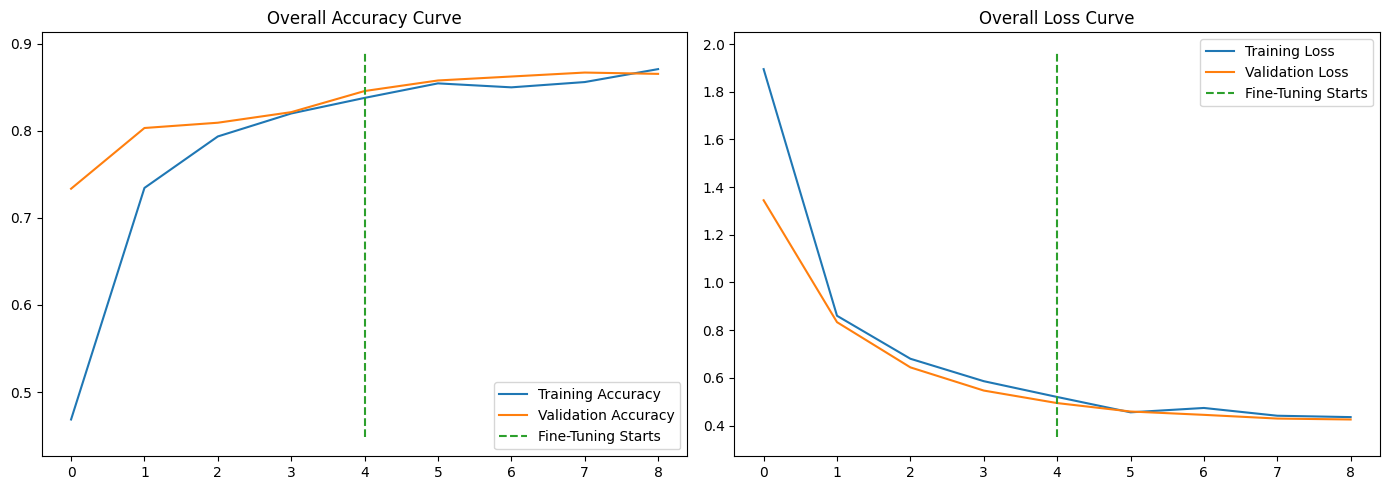

In [ ]:
print("\n--- Starting Phase 2: Fine-Tuning ---")

# Unfreeze base model
base_model.trainable = True

# Refreeze all layers except top 20 layers (reduced depth for faster CPU backprop)
fine_tune_at = len(base_model.layers) - 20
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Ensure BatchNormalization layers stay in inference mode
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

EPOCHS_PHASE2 = 4
total_epochs = len(history_phase1.history['accuracy']) + EPOCHS_PHASE2

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=len(history_phase1.history['accuracy']),
    callbacks=[checkpoint_cb, early_stopping_cb]
)

# Combined Visualizations across both phases
acc_combined = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
val_acc_combined = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']
loss_combined = history_phase1.history['loss'] + history_phase2.history['loss']
val_loss_combined = history_phase1.history['val_loss'] + history_phase2.history['val_loss']

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc_combined, label='Training Accuracy')
plt.plot(val_acc_combined, label='Validation Accuracy')
plt.plot([len(history_phase1.history['accuracy'])-1, len(history_phase1.history['accuracy'])-1],
         plt.ylim(), label='Fine-Tuning Starts', linestyle='--')
plt.legend(loc='lower right')
plt.title('Overall Accuracy Curve')

plt.subplot(1, 2, 2)
plt.plot(loss_combined, label='Training Loss')
plt.plot(val_loss_combined, label='Validation Loss')
plt.plot([len(history_phase1.history['accuracy'])-1, len(history_phase1.history['accuracy'])-1],
         plt.ylim(), label='Fine-Tuning Starts', linestyle='--')
plt.legend(loc='upper right')
plt.title('Overall Loss Curve')
plt.tight_layout()
plt.show()

# ==============================================================
# STEP 12: MODEL EVALUATION & METRICS
# ==============================================================



--- Evaluating Model on Test Dataset ---
21/21 ━━━━━━━━━━━━━━━━━━━━ 16s 735ms/step - accuracy: 0.8576 - loss: 0.4043

Final Test Loss:     0.4043
Final Test Accuracy: 85.76%

--- Scikit-Learn Classification Report ---
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.9565    0.7333    0.8302        30
                              Apple___healthy     0.7179    0.9333    0.8116        30
     Cherry_(including_sour)___Powdery_mildew     1.0000    0.9667    0.9831        30
                       Corn_(maize)___healthy     1.0000    1.0000    1.0000        30
                 Grape___Esca_(Black_Measles)     1.0000    0.9667    0.9831        30
   Grape___Leaf_blight_(Isariopsis_Leaf_Spot)     0.9677    1.0000    0.9836        30
                              Grape___healthy     1.0000    0.9667    0.9831        30
     Orange___Haunglongbing_(Citrus_greening)     1.0000    1.0000    1.0000        

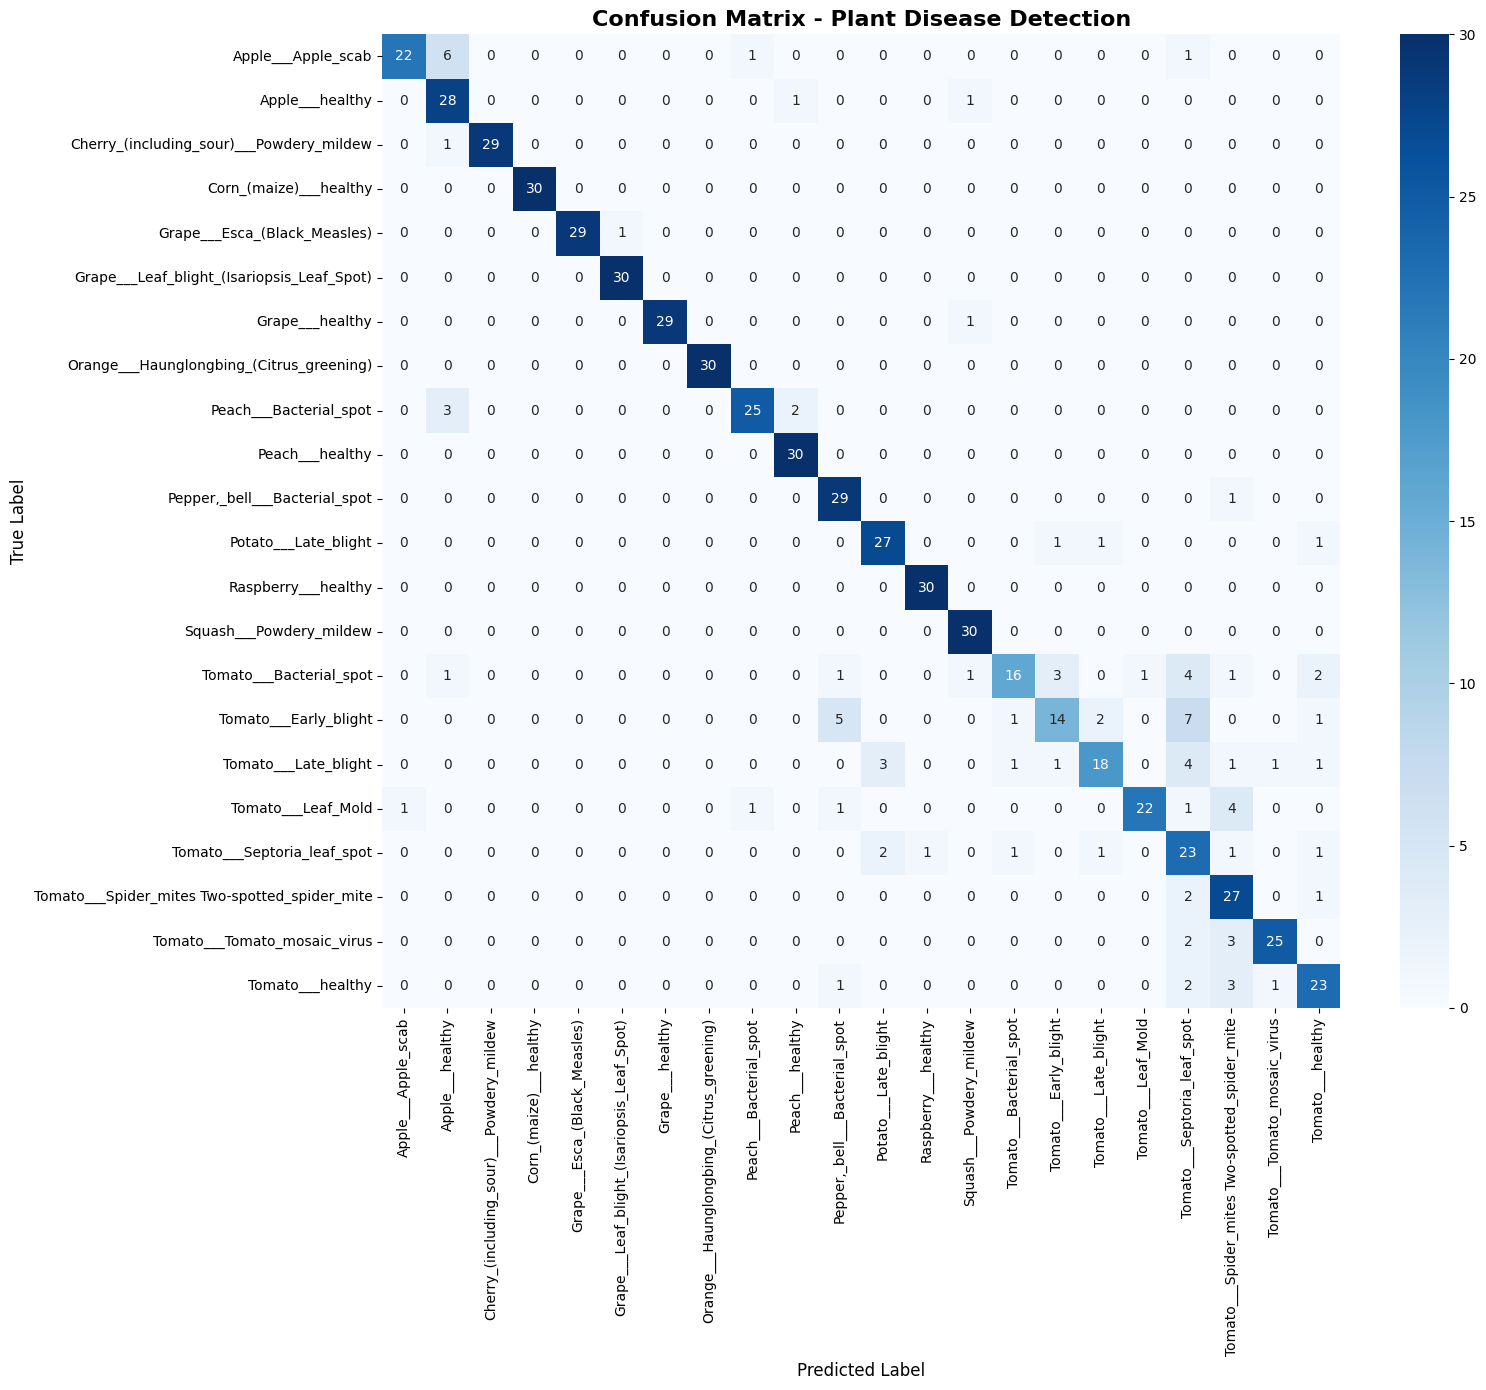

In [ ]:
print("\n--- Evaluating Model on Test Dataset ---")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nFinal Test Loss:     {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%\n")

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("--- Scikit-Learn Classification Report ---")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix - Plant Disease Detection', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================
# STEP 13: SAVE MODEL & CLASS MAPPING
# ==============================================================

Saved complete EfficientNetB0 model to: /content/drive/MyDrive/plant_disease_efficientnetb0_cpu.keras
Saved JSON class mapping to:            /content/drive/MyDrive/plant_disease_classes.json

Running Single-Image Prediction Demonstration on: /content/split_data_fast_cpu/test/Tomato___Late_blight/16b43113-cc8c-4082-a88f-648b79036e49___GHLB_PS Leaf 23.4 Day 13.jpg


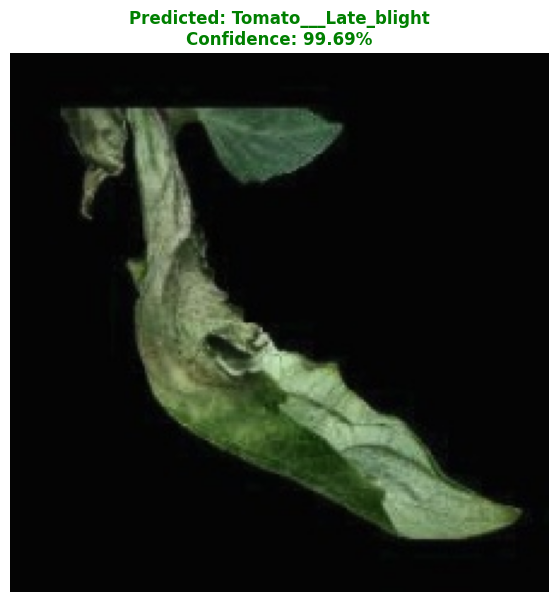


--- Top 3 Predictions ---
1. Tomato___Late_blight: 99.69%
2. Apple___Apple_scab: 0.16%
3. Pepper,_bell___Bacterial_spot: 0.07%


45631

In [ ]:
MODEL_SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)
model.save(str(MODEL_SAVE_PATH))
print(f"Saved complete EfficientNetB0 model to: {MODEL_SAVE_PATH}")

class_mapping = {int(idx): name for idx, name in enumerate(CLASS_NAMES)}
with open(CLASS_JSON_PATH, 'w') as f:
    json.dump(class_mapping, f, indent=4)
print(f"Saved JSON class mapping to:            {CLASS_JSON_PATH}")

if os.path.exists("best_temp_model.keras"):
    os.remove("best_temp_model.keras")

# ==============================================================================
# STEP 14: SINGLE IMAGE PREDICTION INFERENCE FUNCTION
# ==============================================================================
def predict_plant_disease(image_path, model_obj, class_names_list, top_k=3):
    if not os.path.exists(image_path):
        print(f"Error: File not found at '{image_path}'")
        return

    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((128, 128))  # Match downsampled CPU model input dimensions
    img_array = tf.keras.utils.img_to_array(img_resized)
    input_tensor = np.expand_dims(img_array, axis=0)

    predictions = model_obj.predict(input_tensor, verbose=0)[0]
    top_indices = np.argsort(predictions)[::-1][:top_k]

    top_prediction_class = class_names_list[top_indices[0]]
    top_prediction_conf = predictions[top_indices[0]] * 100

    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    plt.title(f"Predicted: {top_prediction_class}\nConfidence: {top_prediction_conf:.2f}%",
              fontsize=12, color='green', fontweight='bold')
    plt.axis("off")
    plt.show()

    print(f"\n--- Top {top_k} Predictions ---")
    for rank, idx in enumerate(top_indices, 1):
        print(f"{rank}. {class_names_list[idx]}: {predictions[idx]*100:.2f}%")

test_sample_images = list(TEST_DIR.rglob('*.jpg')) + list(TEST_DIR.rglob('*.png'))
if test_sample_images:
    demo_img_path = str(test_sample_images[0])
    print(f"\nRunning Single-Image Prediction Demonstration on: {demo_img_path}")
    predict_plant_disease(demo_img_path, model, CLASS_NAMES, top_k=3)

gc.collect()